# Definición y análisis del *Preference Score*

**Objetivo:** Evaluar hasta qué punto la respuesta mejor valorada según el preference score normalizado coincide con la respuesta que presenta un mayor número de upvotes, así como analizar los casos en los que ambos criterios difieren. El objetivo es comprender el efecto de esta normalización por visualizaciones antes de considerar el preference score como posible variable objetivo para los modelos posteriores.

El análisis sigue este orden:

1. Carga y comprobación de datos.
2. Cálculo del preference_score.
3. Selección de preguntas con al menos dos respuestas.
4. Identificación de preguntas con y sin señal de preferencia.
5. Distribución del score.
6. Empates en la respuesta más preferida.
7. Comparación del ganador por upvotes y por preference_score.
8. Análisis de los casos de desacuerdo.
9. Resumen final.

Fórmula utilizada:

$$
\mathrm{preference\_score} =
\frac{\log(\mathrm{upvotes}+1)}
{\log(\mathrm{views}+1)}
$$

La suma de 1 permite incluir respuestas con 0 upvotes. Para views = 0, el score no se calcula.

## Librerías y carga de datos

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

In [3]:
# Fuente pública de CounselChat con las columnas upvotes y views
DATA_URL = (
    "https://huggingface.co/datasets/nbertagnolli/counsel-chat/"
    "raw/main/20220401_counsel_chat.csv"
)

# Si no hay conexión, el cuaderno intentará usar alguno de estos archivos
# si está en la misma carpeta que el notebook
LOCAL_CANDIDATES = [
    Path("20220401_counsel_chat.csv"),
    Path("counselchat-data.csv"),
]

try:
    df = pd.read_csv(DATA_URL)
    fuente = DATA_URL
except Exception:
    archivo_local = next((p for p in LOCAL_CANDIDATES if p.exists()), None)
    if archivo_local is None:
        raise FileNotFoundError(
            "No se pudo descargar el dataset y tampoco se encontró un CSV local. "
            "Coloca '20220401_counsel_chat.csv' en la misma carpeta del notebook."
        )
    df = pd.read_csv(archivo_local)
    fuente = str(archivo_local)

print(f"Fuente: {fuente}")
print(f"Filas: {len(df):,}")
print(f"Preguntas únicas: {df['questionID'].nunique():,}")
print("\nColumnas:")
print(df.columns.tolist())

Fuente: https://huggingface.co/datasets/nbertagnolli/counsel-chat/raw/main/20220401_counsel_chat.csv
Filas: 2,775
Preguntas únicas: 940

Columnas:
['questionID', 'questionTitle', 'questionText', 'questionLink', 'topic', 'therapistInfo', 'therapistURL', 'answerText', 'upvotes', 'views']


In [4]:
# Compruebo que estén las columnas necesarias para este análisis
columnas_necesarias = {
    "questionID",
    "answerText",
    "upvotes",
    "views",
}

faltantes = columnas_necesarias.difference(df.columns)

if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias en el dataset: {sorted(faltantes)}"
    )

print("Columnas necesarias encontradas correctamente.")

Columnas necesarias encontradas correctamente.


## 1. Cálculo del preference_score

Se crea una copia del dataset para no modificar df.

- upvotes y views se convierten a formato numérico.
- Si views > 0, se calcula el score.
- Si views = 0, el score queda como NaN porque el denominador sería 0.

In [5]:
df_score = df.copy()

df_score["upvotes"] = pd.to_numeric(df_score["upvotes"], errors="coerce")
df_score["views"] = pd.to_numeric(df_score["views"], errors="coerce")

# Inicializao el score como NaN y solo lo calculo cuando
# views > 0 y upvotes >= 0
df_score["preference_score"] = np.nan

mask_score = (
    df_score["views"].gt(0)
    & df_score["upvotes"].ge(0)
    & df_score["views"].notna()
    & df_score["upvotes"].notna()
)

df_score.loc[mask_score, "preference_score"] = (
    np.log1p(df_score.loc[mask_score, "upvotes"])
    / np.log1p(df_score.loc[mask_score, "views"])
)

print("Respuestas totales:", len(df_score))
print("Upvotes no numéricos/nulos:", df_score["upvotes"].isna().sum())
print("Views no numéricas/nulas:", df_score["views"].isna().sum())
print("Scores no calculables:", df_score["preference_score"].isna().sum())

df_score[
    ["questionID", "upvotes", "views", "preference_score"]
].head()

Respuestas totales: 2775
Upvotes no numéricos/nulos: 0
Views no numéricas/nulas: 0
Scores no calculables: 0


,questionID,upvotes,views,preference_score
0,0,3,1971,0.182724
1,0,2,386,0.184380
2,0,2,3071,0.136812
3,0,2,2643,0.139417
4,0,1,256,0.124912


## 2. Preguntas con al menos dos respuestas

El objetivo es **rankear respuestas dentro de una misma pregunta**.  
Por ello, una pregunta con una sola respuesta no permite comparar preferencias.

In [6]:
# Para el análisis solo uso filas con los campos esenciales válidos
df_valido = df_score.dropna(
    subset=["questionID", "upvotes", "views", "preference_score"]
).copy()

n_respuestas = df_valido.groupby("questionID").size()

ids_multi = n_respuestas[n_respuestas >= 2].index

df_rank = df_valido[
    df_valido["questionID"].isin(ids_multi)
].copy()

print("Preguntas totales:", df_valido["questionID"].nunique())
print("Preguntas con al menos 2 respuestas:", df_rank["questionID"].nunique())
print("Respuestas incluidas en estas preguntas:", len(df_rank))

Preguntas totales: 940
Preguntas con al menos 2 respuestas: 460
Respuestas incluidas en estas preguntas: 2295


## 3. Preguntas con y sin señal de preferencia

Si todas las respuestas de una pregunta tienen 0 upvotes, todas obtienen preference_score = 0.

En ese caso, los datos **no permiten identificar una respuesta preferida**, por lo que esas preguntas se separan del análisis principal de *top-1*.

In [7]:
max_score_por_pregunta = (
    df_rank.groupby("questionID")["preference_score"]
    .max()
)

ids_sin_preferencia = max_score_por_pregunta[
    max_score_por_pregunta == 0
].index

ids_con_preferencia = max_score_por_pregunta[
    max_score_por_pregunta > 0
].index

print("Preguntas con al menos 2 respuestas:", len(max_score_por_pregunta))
print("Preguntas sin señal de preferencia:", len(ids_sin_preferencia))
print("Preguntas con señal de preferencia:", len(ids_con_preferencia))

Preguntas con al menos 2 respuestas: 460
Preguntas sin señal de preferencia: 184
Preguntas con señal de preferencia: 276


In [8]:
# Dataset principal para estudiar cuál es la respuesta más preferida
df_preferencia = df_rank[
    df_rank["questionID"].isin(ids_con_preferencia)
].copy()

print(
    "Preguntas utilizadas para analizar preferencia:",
    df_preferencia["questionID"].nunique(),
)
print("Respuestas incluidas:", len(df_preferencia))

Preguntas utilizadas para analizar preferencia: 276
Respuestas incluidas: 1732


## 4. Distribución del preference_score

Este análisis permite ver si el score presenta variabilidad, si está muy concentrado cerca de cero y qué proporción de respuestas tiene score igual a 0.

In [9]:
print("Resumen descriptivo del preference_score:")
display(df_rank["preference_score"].describe().to_frame().T)

porcentaje_cero = (df_rank["preference_score"] == 0).mean() * 100
print(f"Respuestas con preference_score = 0: {porcentaje_cero:.2f}%")

Resumen descriptivo del preference_score:


,count,mean,std,min,25%,50%,75%,max
preference_score,2295.000000,0.041602,0.074715,0.000000,0.000000,0.000000,0.096048,0.394708


Respuestas con preference_score = 0: 73.64%


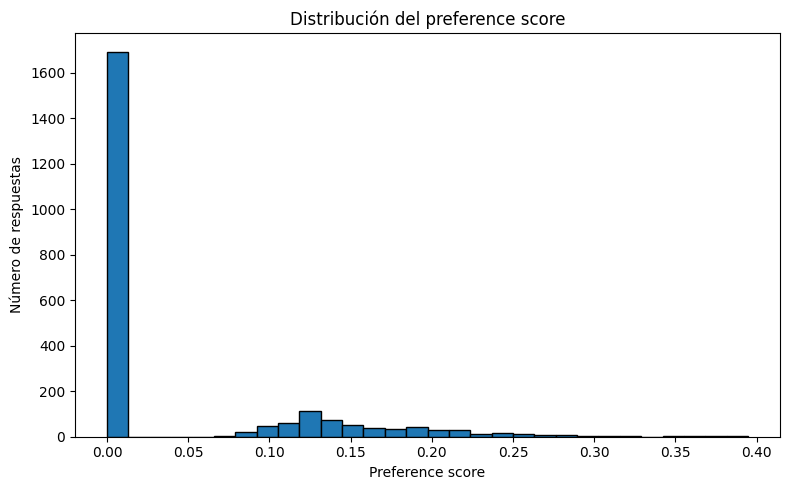

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(
    df_rank["preference_score"].dropna(),
    bins=30,
    edgecolor="black",
)
plt.title("Distribución del preference score")
plt.xlabel("Preference score")
plt.ylabel("Número de respuestas")
plt.tight_layout()
plt.show()

## 5. Empates en el primer puesto

Ahora se comprueba si, dentro de las preguntas **con señal de preferencia**, existen dos o más respuestas con el mismo score máximo.

Esto es importante porque, si hubiera muchos empates, no existiría una única respuesta objetivo para el ranking.

In [11]:
empates = []

for question_id, grupo in df_preferencia.groupby("questionID"):
    max_score = grupo["preference_score"].max()

    n_ganadoras = (grupo["preference_score"] == max_score).sum()

    empates.append({
        "questionID": question_id,
        "n_respuestas": len(grupo),
        "n_ganadoras": int(n_ganadoras),
        "empate_top": n_ganadoras > 1,
    })

empates_df = pd.DataFrame(empates)

n_empates = int(empates_df["empate_top"].sum())
porcentaje_empates = empates_df["empate_top"].mean() * 100

print("Preguntas analizadas:", len(empates_df))
print("Preguntas con empate en el primer puesto:", n_empates)
print(f"Porcentaje con empate: {porcentaje_empates:.2f}%")

Preguntas analizadas: 276
Preguntas con empate en el primer puesto: 0
Porcentaje con empate: 0.00%


In [12]:
# Solo se muestra una tabla si realmente existen empates
if empates_df["empate_top"].any():
    display(empates_df[empates_df["empate_top"]])
else:
    print("No hay empates en el primer puesto entre las preguntas con señal de preferencia.")

No hay empates en el primer puesto entre las preguntas con señal de preferencia.


## 6. Comparación: ganador por upvotes vs. ganador por preference_score

Para cada pregunta:

1. Localizo la respuesta o respuestas con más upvotes.
2. Localizo la respuesta o respuestas con mayor preference_score.
3. Considero que ambos criterios coinciden si tienen **al menos una respuesta ganadora en común**.

Se utilizan conjuntos (set) para tratar correctamente posibles empates en upvotes.

In [13]:
resultados = []

for question_id, grupo in df_preferencia.groupby("questionID"):

    max_upvotes = grupo["upvotes"].max()
    max_score = grupo["preference_score"].max()

    # Puede haber más de una respuesta empatada en upvotes o score
    top_upvotes = set(
        grupo.index[grupo["upvotes"] == max_upvotes]
    )

    top_score = set(
        grupo.index[grupo["preference_score"] == max_score]
    )

    coincide = bool(top_upvotes.intersection(top_score))

    resultados.append({
        "questionID": question_id,
        "coincide": coincide,
        "max_upvotes": max_upvotes,
        "max_score": max_score,
        "n_respuestas": len(grupo),
        "n_top_upvotes": len(top_upvotes),
        "n_top_score": len(top_score),
    })

comparacion = pd.DataFrame(resultados)

porcentaje_coincidencia = comparacion["coincide"].mean() * 100
n_desacuerdos = int((~comparacion["coincide"]).sum())
porcentaje_desacuerdo = 100 - porcentaje_coincidencia

print(f"Preguntas analizadas: {len(comparacion)}")
print(
    "Coincidencia entre ganador por upvotes y ganador por score: "
    f"{porcentaje_coincidencia:.2f}%"
)
print(
    f"Casos de desacuerdo: {n_desacuerdos} "
    f"({porcentaje_desacuerdo:.2f}%)"
)

Preguntas analizadas: 276
Coincidencia entre ganador por upvotes y ganador por score: 99.64%
Casos de desacuerdo: 1 (0.36%)


## 7. Casos de desacuerdo

Se muestran únicamente las preguntas en las que el ganador por upvotes y el ganador por preference_score no coinciden.

Las columnas top_upvotes y top_score permiten ver directamente qué respuesta gana según cada criterio.

In [14]:
ids_desacuerdo = comparacion.loc[
    ~comparacion["coincide"],
    "questionID",
].tolist()

if not ids_desacuerdo:
    print("No existen casos de desacuerdo.")
else:
    desacuerdos = df_preferencia[
        df_preferencia["questionID"].isin(ids_desacuerdo)
    ].copy()

    desacuerdos["top_upvotes"] = desacuerdos.groupby("questionID")[
        "upvotes"
    ].transform("max").eq(desacuerdos["upvotes"])

    desacuerdos["top_score"] = desacuerdos.groupby("questionID")[
        "preference_score"
    ].transform("max").eq(desacuerdos["preference_score"])

    desacuerdos = desacuerdos.sort_values(
        ["questionID", "preference_score"],
        ascending=[True, False],
    )

    columnas_mostrar = [
        "questionID",
        "answerText",
        "upvotes",
        "views",
        "preference_score",
        "top_upvotes",
        "top_score",
    ]

    display(desacuerdos[columnas_mostrar])

,questionID,answerText,upvotes,views,preference_score,top_upvotes,top_score
1,0,"I've never heard of someone having ""too many issues"" for therapy to be effective. A competent therapist will assist ...",2,386,0.184380,False,True
0,0,It is very common for people to have multiple issues that they want to (and need to) address in counseling. I have ...,3,1971,0.182724,True,False
3,0,"Let me start by saying there are never too many concerns that you can bring into counselling. In fact, most people w...",2,2643,0.139417,False,False
2,0,Absolutely not. I strongly recommending working on one issue/need at a time. In therapy you will set smart goals a...,2,3071,0.136812,False,False
6,0,There is no such thing as too much. Start where you're at today and move forward or backwards to figure out the rest...,1,217,0.128730,False,False
...,...,...,...,...,...,...,...
81,0,The way it goes is that all your issues are connected. Once you work on one issue it will have a positive effect on ...,0,123,0.000000,False,False
82,0,I think this is a very common question that people who have never been to counseling before have. There is a lot of...,0,119,0.000000,False,False
83,0,"Hello, I'm so glad you decided to take the first step in opening a conversation first. Deciding to go to therapy can...",0,119,0.000000,False,False
84,0,"Not at all my dear. Human beings are complex creatures, and in my opinion, our issues interconnect in a very nuanced...",0,607,0.000000,False,False


En el único caso de desacuerdo, la respuesta con más upvotes no es la que obtiene el mayor preference score. La respuesta ganadora por upvotes tiene 3 votos y 1971 visualizaciones, mientras que la ganadora por score tiene 2 votos pero solo 386 visualizaciones. Esto muestra que la normalización por visualizaciones puede favorecer respuestas con menor exposición relativa, aunque en el conjunto global este efecto es muy poco frecuente.

## 8. Resumen final del análisis


In [15]:
n_multi = df_rank["questionID"].nunique()
n_sin = len(ids_sin_preferencia)
n_con = df_preferencia["questionID"].nunique()
n_empates = int(empates_df["empate_top"].sum())
n_coinciden = int(comparacion["coincide"].sum())
n_desacuerdos = int((~comparacion["coincide"]).sum())

print("RESUMEN")
print("-------")
print(f"Preguntas con al menos 2 respuestas: {n_multi}")
print(f"Preguntas sin señal de preferencia: {n_sin}")
print(f"Preguntas con señal de preferencia: {n_con}")
print(f"Empates en el top entre preguntas con señal: {n_empates}")
print(
    f"Coincidencia top-1 upvotes vs score: "
    f"{n_coinciden}/{len(comparacion)} "
    f"({porcentaje_coincidencia:.2f}%)"
)
print(
    f"Desacuerdos top-1: "
    f"{n_desacuerdos}/{len(comparacion)} "
    f"({porcentaje_desacuerdo:.2f}%)"
)

RESUMEN
-------
Preguntas con al menos 2 respuestas: 460
Preguntas sin señal de preferencia: 184
Preguntas con señal de preferencia: 276
Empates en el top entre preguntas con señal: 0
Coincidencia top-1 upvotes vs score: 275/276 (99.64%)
Desacuerdos top-1: 1/276 (0.36%)


### Interpretación

- **460** preguntas tienen al menos dos respuestas.
- **184** no presentan señal de preferencia porque todas sus respuestas tienen score 0.
- Quedan **276** preguntas con señal de preferencia.
- No hay empates en el primer puesto entre esas 276 preguntas.
- En **275 de 276 (99,64 %)** coincide la respuesta ganadora por upvotes y por preference_score.
- Solo existe **1 desacuerdo (0,36 %)**.

Esto indica que la normalización por visualizaciones **apenas modifica la elección de la respuesta top-1** en este dataset, aunque el score sigue incorporando explícitamente la exposición de cada respuesta.


## 9. Predicción de la respuesta más preferida

Una vez analizado el preference_score, se plantea como primera tarea comprobar si es posible identificar, dada una pregunta con varias respuestas candidatas, cuál es la respuesta más preferida por los usuarios.

En esta primera aproximación se aborda únicamente la identificación de la respuesta top-1, sin intentar todavía ordenar todas las respuestas de mayor a menor preferencia.

In [16]:
columnas_finales = [
    "questionID",
    "questionText",
    "answerText",
    "upvotes",
    "views",
    "preference_score",
]

columnas_finales = [
    c for c in columnas_finales
    if c in df_preferencia.columns
]

df_preferencia[columnas_finales].head()

,questionID,questionText,answerText,upvotes,views,preference_score
0,0,"I have so many issues to address. I have a history of sexual abuse, I’m a breast cancer survivor and I am a lifetime...",It is very common for people to have multiple issues that they want to (and need to) address in counseling. I have ...,3,1971,0.182724
1,0,"I have so many issues to address. I have a history of sexual abuse, I’m a breast cancer survivor and I am a lifetime...","I've never heard of someone having ""too many issues"" for therapy to be effective. A competent therapist will assist ...",2,386,0.184380
2,0,"I have so many issues to address. I have a history of sexual abuse, I’m a breast cancer survivor and I am a lifetime...",Absolutely not. I strongly recommending working on one issue/need at a time. In therapy you will set smart goals a...,2,3071,0.136812
3,0,"I have so many issues to address. I have a history of sexual abuse, I’m a breast cancer survivor and I am a lifetime...","Let me start by saying there are never too many concerns that you can bring into counselling. In fact, most people w...",2,2643,0.139417
4,0,"I have so many issues to address. I have a history of sexual abuse, I’m a breast cancer survivor and I am a lifetime...",I just want to acknowledge you for the courage to take the step to get support. It can be overwhelming to have so ma...,1,256,0.124912


Para cada pregunta, se considera como respuesta preferida aquella que presenta el mayor preference_score. Se define una variable binaria target, donde la respuesta preferida recibe la etiqueta 1 y el resto de respuestas la etiqueta 0.

De esta forma, el objetivo del modelo será identificar cuál de las respuestas candidatas corresponde a la respuesta más preferida según el score normalizado.

In [17]:
df_modelo = df_preferencia.copy()

df_modelo["target"] = (
    df_modelo["preference_score"]
    == df_modelo.groupby("questionID")["preference_score"].transform("max")
).astype(int)

Compruebo que todo esté bien:

In [18]:
ganadoras = df_modelo.groupby("questionID")["target"].sum()

print("Preguntas:", len(ganadoras))
print("Con una única respuesta preferida:", (ganadoras == 1).sum())
print("Problemáticas:", (ganadoras != 1).sum())

Preguntas: 276
Con una única respuesta preferida: 276
Problemáticas: 0


El conjunto de datos se divide en entrenamiento, validación y prueba utilizando questionID como unidad de separación. De esta forma, todas las respuestas asociadas a una misma pregunta permanecen en el mismo subconjunto, evitando que información de una pregunta utilizada durante el entrenamiento aparezca también en validación o test.

Se utiliza una división aproximada del 60 % para entrenamiento, 20 % para validación y 20 % para test.

In [19]:
from sklearn.model_selection import train_test_split

question_ids = df_modelo["questionID"].unique()

train_ids, test_ids = train_test_split(
    question_ids,
    test_size=0.20,
    random_state=27
)

train_ids, val_ids = train_test_split(
    train_ids,
    test_size=0.25,
    random_state=27
)

train = df_modelo[
    df_modelo["questionID"].isin(train_ids)
].copy()

val = df_modelo[
    df_modelo["questionID"].isin(val_ids)
].copy()

test = df_modelo[
    df_modelo["questionID"].isin(test_ids)
].copy()

print("Train:", train["questionID"].nunique())
print("Validation:", val["questionID"].nunique())
print("Test:", test["questionID"].nunique())

Train: 165
Validation: 55
Test: 56


### Baselines simples

Antes de evaluar el modelo TF-IDF + regresión logística, se consideran varios baselines sencillos sobre el mismo conjunto de prueba. El objetivo es establecer referencias mínimas que permitan valorar posteriormente si el modelo basado en texto aporta una mejora real.

Se consideran las siguientes estrategias:

- Selección aleatoria de una respuesta.
- Selección de la respuesta más larga.
- Selección de la respuesta más corta.
- Selección de la respuesta con mayor solapamiento léxico con la pregunta.

Todos los métodos se evalúan mediante Accuracy@1, utilizando exactamente las mismas preguntas del conjunto de test.**texto en negrita**

#### 1.Baseline aleatorio

Como cada pregunta tiene distinto número de respuestas, calculo la Accuracy@1 esperada del azar. Por ejemplo, para una pregunta con 5 respuestas, la probabilidad de acertar al azar es 1/5.

In [20]:
# Baseline aleatorio: Accuracy@1 esperada

n_respuestas_test = test.groupby("questionID").size()

accuracy_random = (1 / n_respuestas_test).mean()

print(f"Baseline aleatorio, Accuracy@1: {accuracy_random:.2%}")

Baseline aleatorio, Accuracy@1: 32.12%


#### 2.Respuesta más larga y más corta

Primero calculo la longitud en número de palabras:

In [21]:
test["longitud_respuesta"] = (
    test["answerText"]
    .fillna("")
    .str.split()
    .str.len()
)

He añadido esta función para tratar de manera reproducible posibles empates (al azar pero con semilla):

In [22]:
def seleccionar_por_metrica(df, columna, modo="max", seed=27):
    rng = np.random.default_rng(seed)
    seleccionadas = []

    for _, grupo in df.groupby("questionID"):
        if modo == "max":
            valor = grupo[columna].max()
        else:
            valor = grupo[columna].min()

        candidatas = grupo.index[
            grupo[columna] == valor
        ].to_numpy()

        seleccionadas.append(rng.choice(candidatas))

    return df.loc[seleccionadas]

Respuesta más larga:

In [23]:
pred_larga = seleccionar_por_metrica(
    test,
    "longitud_respuesta",
    modo="max"
)

accuracy_larga = pred_larga["target"].mean()

print(f"Respuesta más larga, Accuracy@1: {accuracy_larga:.2%}")

Respuesta más larga, Accuracy@1: 41.07%


Y la más corta:

In [24]:
pred_corta = seleccionar_por_metrica(
    test,
    "longitud_respuesta",
    modo="min"
)

accuracy_corta = pred_corta["target"].mean()

print(f"Respuesta más corta, Accuracy@1: {accuracy_corta:.2%}")

Respuesta más corta, Accuracy@1: 25.00%


#### 3.Baseline de solapamiento léxico

En este caso, gana la respuesta que comparte una mayor proporción de palabras relevantes con la pregunta.

In [25]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stopwords = set(ENGLISH_STOP_WORDS)

def obtener_palabras(texto):
    palabras = re.findall(r"[a-zA-Z']+", str(texto).lower())

    return {
        palabra
        for palabra in palabras
        if palabra not in stopwords
    }

def calcular_solapamiento(fila):
    palabras_pregunta = obtener_palabras(fila["questionText"])
    palabras_respuesta = obtener_palabras(fila["answerText"])

    if len(palabras_pregunta) == 0:
        return 0

    return len(
        palabras_pregunta & palabras_respuesta
    ) / len(palabras_pregunta)

test["solapamiento_lexico"] = test.apply(
    calcular_solapamiento,
    axis=1
)

pred_solapamiento = seleccionar_por_metrica(
    test,
    "solapamiento_lexico",
    modo="max"
)

accuracy_solapamiento = pred_solapamiento["target"].mean()

print(
    f"Mayor solapamiento léxico, Accuracy@1: "
    f"{accuracy_solapamiento:.2%}"
)

Mayor solapamiento léxico, Accuracy@1: 35.71%


### TF-IDF + regresión logística

##### Preparación del texto de entrada

Para cada respuesta candidata se combina el texto de la pregunta con el texto de la respuesta. Esta será la única información utilizada por el modelo para realizar la predicción. Variables como upvotes, views o preference_score no se utilizan como entrada, ya que contienen información relacionada con la definición de la respuesta objetivo.

In [26]:
train["texto"] = (
    train["questionText"].fillna("")
    + " "
    + train["answerText"].fillna("")
)

val["texto"] = (
    val["questionText"].fillna("")
    + " "
    + val["answerText"].fillna("")
)

test["texto"] = (
    test["questionText"].fillna("")
    + " "
    + test["answerText"].fillna("")
)

Como primera aproximación sencilla, los textos se representan mediante TF-IDF y se entrena un modelo de regresión logística para estimar la probabilidad de que cada respuesta sea la respuesta preferida.

Para cada pregunta del conjunto de prueba, se selecciona como predicción la respuesta candidata con mayor probabilidad estimada.

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train = vectorizer.fit_transform(train["texto"])
X_test = vectorizer.transform(test["texto"])

modelo = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=27
)

modelo.fit(X_train, train["target"])

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=27)

Evaluación: El rendimiento se evalúa mediante Accuracy@1, definida como el porcentaje de preguntas para las que el modelo identifica correctamente la respuesta con mayor preference_score.

In [28]:
test["prob_preferida"] = modelo.predict_proba(X_test)[:, 1]

In [29]:
predicciones = test.loc[
    test.groupby("questionID")["prob_preferida"].idxmax()
]

accuracy_top1 = predicciones["target"].mean()

print(f"Accuracy@1: {accuracy_top1:.2%}")

Accuracy@1: 33.93%


Como primera aproximación, se ha planteado la identificación de la respuesta más preferida como un problema binario, utilizando el preference_score para definir la respuesta objetivo. Con una representación TF-IDF y regresión logística, el modelo obtiene una Accuracy@1 del 33,93 % en el conjunto de prueba. Este resultado sirve como primera referencia para evaluar posteriormente modelos con representaciones semánticas más avanzadas.

In [30]:
resultados = pd.DataFrame({
    "Método": [
        "Aleatorio",
        "Respuesta más larga",
        "Respuesta más corta",
        "Solapamiento léxico",
        "TF-IDF + Regresión Logística"
    ],
    "Accuracy@1": [
        accuracy_random,
        accuracy_larga,
        accuracy_corta,
        accuracy_solapamiento,
        accuracy_top1
    ]
})

resultados["Accuracy@1 (%)"] = (
    resultados["Accuracy@1"] * 100
)

resultados = resultados[
    ["Método", "Accuracy@1 (%)"]
]

display(resultados.round(2))

,Método,Accuracy@1 (%)
0,Aleatorio,32.120000
1,Respuesta más larga,41.070000
2,Respuesta más corta,25.000000
3,Solapamiento léxico,35.710000
4,TF-IDF + Regresión Logística,33.930000


Los resultados muestran que el baseline basado en seleccionar la respuesta más larga obtiene el mejor rendimiento, con una Accuracy@1 del 41,07 %. Le siguen el solapamiento léxico (35,71 %) y el modelo TF-IDF + regresión logística (33,93 %). Este último apenas mejora el rendimiento esperado de una selección aleatoria (32,12 %), mientras que seleccionar la respuesta más corta obtiene el peor resultado (25,00 %).

Estos resultados sugieren que la longitud de la respuesta contiene una señal relevante para identificar la respuesta preferida en este conjunto de datos. En cambio, el modelo TF-IDF utilizado en esta primera aproximación no consigue aprovechar suficientemente la información textual como para superar los baselines más sencillos.

# Relaciones entre usuarios, preguntas y respuestas

In [31]:
print(df.columns.tolist())

['questionID', 'questionTitle', 'questionText', 'questionLink', 'topic', 'therapistInfo', 'therapistURL', 'answerText', 'upvotes', 'views']


Aunque cada pregunta dispone de un questionID, no existe un identificador del usuario que la formuló ni identificar quien vota. Por tanto, no es posible determinar si distintas preguntas pertenecen al mismo usuario o estudiar la recurrencia de los usuarios que realizan consultas.

## Recurrencia de los porfesionales en el dataset

In [32]:
df_prof = df.dropna(subset=["therapistURL"]).copy()

profesionales = (
    df_prof.groupby("therapistURL")
    .agg(
        n_respuestas=("answerText", "size"),
        n_preguntas=("questionID", "nunique"),
        therapistInfo=("therapistInfo", "first")
    )
    .sort_values("n_respuestas", ascending=False)
)

print("Profesionales identificados:", len(profesionales))
print(
    "Profesionales que responden a una sola pregunta:",
    (profesionales["n_preguntas"] == 1).sum()
)
print(
    "Profesionales que responden a más de una pregunta:",
    (profesionales["n_preguntas"] > 1).sum()
)

display(profesionales.head(10))

Profesionales identificados: 433
Profesionales que responden a una sola pregunta: 153
Profesionales que responden a más de una pregunta: 280


,n_respuestas,n_preguntas,therapistInfo
therapistURL,,,
https://counselchat.com/therapists/sherry-katz-lcsw,497,497,"Sherry Katz, LCSWCouples and Family Therapist, LCSW"
https://counselchat.com/therapists/lauren-ostrowski-ma-lpc-ncc-bc-tmh-cctp-cch,146,146,"Lauren Ostrowski, MA, LPC, NCC, BC-TMH, CCTP, CCHI tailor my therapeutic approach to each client's strengths and goals"
https://counselchat.com/therapists/ms-lynda-martens-london-ontario,127,127,"Lynda MartensMarriage & Family Therapist, MSc, RP, RMFT"
https://counselchat.com/therapists/kaileen-mcmickle-ms-lpc,84,84,"Kaileen McMickle, MS, LPCLicensed Professional Counselor"
https://counselchat.com/therapists/dr-meredyth-lawrynce,64,64,Dr. Meredyth LawrynceServing Clients Nationwide
https://counselchat.com/therapists/dr-traci-kochendorfer,47,47,"Dr Traci KochendorferTime for you to "" Claim IT"" with over 15 years in health and wellness, Ph.D Psy.D D.D. F.P.L.C...."
https://counselchat.com/therapists/robin-landwehr-dbh-lpcc-ncc,46,46,"Robin Landwehr, DBH, LPCC, NCCMental Health in a Primary Care Setting"
https://counselchat.com/therapists/vivian-d-echevarria-guzman-msc-lpc-s-ncc,45,45,"Vivian D. Echevarria Guzman, MSC, LPC-S, NCCBilingual Licensed Professional Counselor"
https://counselchat.com/therapists/sonya-wilson,44,44,Sonya WilsonLicensed Professional Counselor


Se identifican 433 profesionales. De ellos, 280 responden a más de una pregunta y 153 aparecen solo una vez. Esto indica que existe una recurrencia notable de profesionales en el dataset.

In [33]:
n_profesionales = len(profesionales)

pct_una = (
    (profesionales["n_preguntas"] == 1).mean() * 100
)

pct_varias = (
    (profesionales["n_preguntas"] > 1).mean() * 100
)

print(f"Profesionales con una sola pregunta: {pct_una:.2f}%")
print(f"Profesionales con varias preguntas: {pct_varias:.2f}%")
print(
    "Máximo de preguntas respondidas por un mismo profesional:",
    profesionales["n_preguntas"].max()
)

Profesionales con una sola pregunta: 35.33%
Profesionales con varias preguntas: 64.67%
Máximo de preguntas respondidas por un mismo profesional: 497


El 64,67 % de los profesionales responde a más de una pregunta, frente al 35,33 % que aparece una sola vez. Además, existe una participación muy desigual, ya que el profesional más activo responde a 497 preguntas.

## Profesionales por pregunta

In [34]:
profesionales_por_pregunta = (
    df_prof.groupby("questionID")["therapistURL"]
    .nunique()
)

print(profesionales_por_pregunta.describe())

print(
    "Preguntas respondidas por más de un profesional:",
    (profesionales_por_pregunta > 1).sum()
)

print(
    "Porcentaje:",
    f"{(profesionales_por_pregunta > 1).mean() * 100:.2f}%"
)

count   940.000000
mean      2.952128
std       6.309623
min       1.000000
25%       1.000000
50%       1.000000
75%       3.000000
max     107.000000
Name: therapistURL, dtype: float64
Preguntas respondidas por más de un profesional: 460
Porcentaje: 48.94%


El 48,94 % de las preguntas recibe respuestas de más de un profesional. La mediana es de 1 profesional por pregunta, aunque existen casos con una participación mucho mayor, llegando a un máximo de 107 profesionales en una misma pregunta.

## Diversidad temática de los profesionales

In [35]:
temas_por_profesional = (
    df_prof.groupby("therapistURL")["topic"]
    .nunique()
)

print(temas_por_profesional.describe())

print(
    "Profesionales que aparecen en más de un tema:",
    (temas_por_profesional > 1).sum()
)

count   433.000000
mean      3.143187
std       3.548970
min       1.000000
25%       1.000000
50%       2.000000
75%       4.000000
max      29.000000
Name: topic, dtype: float64
Profesionales que aparecen en más de un tema: 263


Los profesionales aparecen, de media, en 3,14 temas distintos, y 263 de 433 participan en más de un tema. Esto indica que muchos profesionales no están asociados a una única temática dentro del dataset.

## Interacción (upvotes y views) recibida por profesional

Se analiza de forma descriptiva la interacción recibida por los profesionales con al menos 5 respuestas (para evitar conclusiones basadas en una única respuesta), utilizando la mediana de upvotes y views para reducir el efecto de valores extremos.


In [36]:
estadisticas_profesionales = (
    df_prof.groupby("therapistURL")
    .agg(
        n_respuestas=("answerText", "size"),
        mediana_upvotes=("upvotes", "median"),
        mediana_views=("views", "median")
    )
)

profesionales_recurrentes = estadisticas_profesionales[
    estadisticas_profesionales["n_respuestas"] >= 5
]

display(
    profesionales_recurrentes
    .sort_values("mediana_upvotes", ascending=False)
    .head(10)
)

,n_respuestas,mediana_upvotes,mediana_views
therapistURL,,,
https://counselchat.com/therapists/virginia-chow,6,9.000000,1658.500000
https://counselchat.com/therapists/tamara-powell,10,2.500000,1806.000000
https://counselchat.com/therapists/rebecca-duellman,8,2.500000,312.500000
https://counselchat.com/therapists/todd-schmenk-m-s-m-ed,6,2.500000,454.000000
https://counselchat.com/therapists/jessica-dobbs,8,2.000000,246.500000
https://counselchat.com/therapists/eric-str-m-jd-ma-lmhc,39,2.000000,502.000000
https://counselchat.com/therapists/daniel-kelley-petersen,5,2.000000,350.000000
https://counselchat.com/therapists/nat-roman-toronto,23,2.000000,358.000000
https://counselchat.com/therapists/cimberly-r-nesker,17,1.000000,281.000000


In [37]:
print(
    profesionales_recurrentes[
        ["mediana_upvotes", "mediana_views"]
    ].describe()
)

       mediana_upvotes  mediana_views
count       105.000000     105.000000
mean          0.390476     196.323810
std           1.053796     239.127681
min           0.000000      20.000000
25%           0.000000      96.000000
50%           0.000000     140.500000
75%           0.000000     200.500000
max           9.000000    1806.000000


Entre los 105 profesionales analizados, la mediana de upvotes es 0 y el 75 % presenta también una mediana de 0, lo que refleja la escasez general de votos en el dataset. En cambio, las visualizaciones muestran mayor variabilidad, con una mediana de 140,5 views por respuesta y diferencias considerables entre profesionales.

# Viabilidad de un split sin profesionales compartidos

Para evaluar la capacidad de generalización a profesionales no vistos, se estudia la posibilidad de realizar una división train-test en la que no exista solapamiento de profesionales entre ambos conjuntos. Al mismo tiempo, todas las respuestas correspondientes a una misma pregunta deben permanecer en el mismo conjunto.

In [38]:
import networkx as nx

# Solo necesitamos pregunta y profesional
relaciones = (
    df_modelo[["questionID", "therapistURL"]]
    .dropna()
    .drop_duplicates()
)

G = nx.Graph()

for _, fila in relaciones.iterrows():
    pregunta = f"q_{fila['questionID']}"
    profesional = f"t_{fila['therapistURL']}"

    G.add_edge(pregunta, profesional)

componentes = list(nx.connected_components(G))

print("Número de componentes independientes:", len(componentes))

tamanos = [len(c) for c in componentes]

print("Tamaño del componente más grande:", max(tamanos))
print("Mediana del tamaño:", pd.Series(tamanos).median())

Número de componentes independientes: 1
Tamaño del componente más grande: 690
Mediana del tamaño: 690.0


In [39]:
preguntas_por_componente = []

for i, componente in enumerate(componentes):
    preguntas = [
        nodo for nodo in componente
        if nodo.startswith("q_")
    ]

    preguntas_por_componente.append({
        "componente": i,
        "n_preguntas": len(preguntas)
    })

componentes_df = pd.DataFrame(preguntas_por_componente)

display(
    componentes_df
    .sort_values("n_preguntas", ascending=False)
    .head(10)
)

print(
    "Preguntas en el componente más grande:",
    componentes_df["n_preguntas"].max()
)

,componente,n_preguntas
0,0,276


Preguntas en el componente más grande: 276


Todas las 276 preguntas pertenecen a un único componente conectado a través de los profesionales que las responden. Por tanto, no es posible realizar una separación estricta train-test sin profesionales compartidos manteniendo todas las preguntas completas.

# División train-test

Dado que no es posible realizar una separación estricta por profesional, se realiza un split 80/20 por questionID, manteniendo todas las respuestas de una misma pregunta en el mismo conjunto.

In [40]:
from sklearn.model_selection import train_test_split

question_ids = df_modelo["questionID"].unique()

train_ids, test_ids = train_test_split(
    question_ids,
    test_size=0.20,
    random_state=27
)

train = df_modelo[
    df_modelo["questionID"].isin(train_ids)
].copy()

test = df_modelo[
    df_modelo["questionID"].isin(test_ids)
].copy()

print("Train:", train["questionID"].nunique())
print("Test:", test["questionID"].nunique())

Train: 220
Test: 56


A continuación se cuantifica el solapamiento de profesionales entre train y test para conocer hasta qué punto aparecen profesionales ya vistos durante el entrenamiento.

In [41]:
prof_train = set(train["therapistURL"].dropna())
prof_test = set(test["therapistURL"].dropna())

prof_comunes = prof_train & prof_test

print("Profesionales en train:", len(prof_train))
print("Profesionales en test:", len(prof_test))
print("Profesionales presentes en ambos:", len(prof_comunes))

print(
    "Porcentaje de profesionales de test ya vistos en train:",
    f"{len(prof_comunes) / len(prof_test) * 100:.2f}%"
)

Profesionales en train: 394
Profesionales en test: 122
Profesionales presentes en ambos: 102
Porcentaje de profesionales de test ya vistos en train: 83.61%


El 83,62 % de los profesionales presentes en test también aparecen en train, lo que confirma un solapamiento elevado. Este aspecto se tendrá en cuenta como una limitación al evaluar la generalización a profesionales no vistos.

## Cross-validation sobre el conjunto de entrenamiento

Dado el tamaño reducido del conjunto de datos, no se reserva un conjunto de validación independiente. La selección de modelos e hiperparámetros se realizará mediante validación cruzada sobre el conjunto de entrenamiento.

Los folds se construyen utilizando questionID como grupo, de forma que todas las respuestas correspondientes a una misma pregunta permanezcan siempre juntas y no exista fuga de información entre entrenamiento y validación.

In [42]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(
        train,
        y=train["target"],
        groups=train["questionID"]
    ),
    start=1
):
    train_fold = train.iloc[train_idx]
    val_fold = train.iloc[val_idx]

    print(
        f"Fold {fold}: "
        f"{train_fold['questionID'].nunique()} preguntas train | "
        f"{val_fold['questionID'].nunique()} preguntas validación"
    )

Fold 1: 177 preguntas train | 43 preguntas validación
Fold 2: 176 preguntas train | 44 preguntas validación
Fold 3: 177 preguntas train | 43 preguntas validación
Fold 4: 176 preguntas train | 44 preguntas validación
Fold 5: 174 preguntas train | 46 preguntas validación
